In [1]:
import pandas as pd

cols = ["age","sex","cp","trestbps","chol","fbs","restecg",
        "thalach","exang","oldpeak","slope","ca","thal","num"]

base = "data/heart+disease/"
files = {
    "cleveland":   base + "processed.cleveland.data",
    "hungarian":   base + "processed.hungarian.data",
    "switzerland": base + "processed.switzerland.data",
    "va":          base + "processed.va.data",
}

dfs = {}
for name, path in files.items():
    d = pd.read_csv(path, header=None, names=cols, na_values="?")
    d["target"] = (d["num"] > 0).astype(int)
    dfs[name] = d
    print(name, d.shape)
    print(d.isna().sum()[d.isna().sum() > 0].to_dict())
    print(d["target"].value_counts().to_dict(), "\n")

cleveland (303, 15)
{'ca': 4, 'thal': 2}
{0: 164, 1: 139} 

hungarian (294, 15)
{'trestbps': 1, 'chol': 23, 'fbs': 8, 'restecg': 1, 'thalach': 1, 'exang': 1, 'slope': 190, 'ca': 291, 'thal': 266}
{0: 188, 1: 106} 

switzerland (123, 15)
{'trestbps': 2, 'fbs': 75, 'restecg': 1, 'thalach': 1, 'exang': 1, 'oldpeak': 6, 'slope': 17, 'ca': 118, 'thal': 52}
{1: 115, 0: 8} 

va (200, 15)
{'trestbps': 56, 'chol': 7, 'fbs': 7, 'thalach': 53, 'exang': 53, 'oldpeak': 56, 'slope': 102, 'ca': 198, 'thal': 166}
{1: 149, 0: 51} 



In [3]:
import numpy as np

for name, d in dfs.items():
    d["chol"] = d["chol"].replace(0, np.nan)
    d["trestbps"] = d["trestbps"].replace(0, np.nan)
    print(name, "chol missing:", d["chol"].isna().sum(),
          "| trestbps missing:", d["trestbps"].isna().sum())

cleveland chol missing: 0 | trestbps missing: 0
hungarian chol missing: 23 | trestbps missing: 1
switzerland chol missing: 123 | trestbps missing: 2
va chol missing: 56 | trestbps missing: 57


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             recall_score, precision_score, roc_auc_score)

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

df = dfs["cleveland"]
X = df[num_cols + cat_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

logreg = Pipeline([("prep", preprocess),
                   ("model", LogisticRegression(max_iter=1000))])
logreg.fit(X_train, y_train)

pred = logreg.predict(X_test)
proba = logreg.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))


[[27  6]
 [ 2 26]]
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61

ROC-AUC: 0.9577922077922079


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             eval_metric="logloss", random_state=42),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
rows = []
fitted = {}

for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)])
    scores = cross_validate(pipe, X, y, cv=cv,
                            scoring=["recall", "precision", "roc_auc"])
    rows.append({
        "model": name,
        "recall": scores["test_recall"].mean(),
        "precision": scores["test_precision"].mean(),
        "roc_auc": scores["test_roc_auc"].mean(),
    })
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    print(name)
    print(confusion_matrix(y_test, pipe.predict(X_test)), "\n")

pd.DataFrame(rows).round(3)

Logistic Regression
[[27  6]
 [ 2 26]] 

Random Forest
[[28  5]
 [ 2 26]] 

XGBoost
[[27  6]
 [ 2 26]] 



,model,recall,precision,roc_auc
0,Logistic Regression,0.781,0.856,0.913
1,Random Forest,0.776,0.835,0.907
2,XGBoost,0.773,0.820,0.888


In [6]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

pipe = Pipeline([("prep", preprocess),
                 ("model", LogisticRegression(max_iter=1000))])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_cv = cross_val_predict(pipe, X, y, cv=cv5, method="predict_proba")[:, 1]

rows = []
for t in [0.5, 0.4, 0.3, 0.25, 0.2]:
    pred_t = (proba_cv >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred_t).ravel()
    rows.append({"threshold": t,
                 "recall": tp / (tp + fn),
                 "precision": tp / (tp + fp),
                 "missed_sick": fn,
                 "false_alarms": fp})

pd.DataFrame(rows).round(3)


,threshold,recall,precision,missed_sick,false_alarms
0,0.50,0.791,0.866,29,17
1,0.40,0.835,0.811,23,27
2,0.30,0.878,0.735,17,44
3,0.25,0.906,0.704,13,53
4,0.20,0.928,0.686,10,59


In [7]:
feat_num = ["age", "trestbps", "chol", "thalach", "oldpeak"]
feat_cat = ["sex", "cp", "fbs", "restecg", "exang"]
feats = feat_num + feat_cat

prep2 = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), feat_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), feat_cat),
])

pipe2 = Pipeline([("prep", prep2), ("model", LogisticRegression(max_iter=1000))])
train = dfs["cleveland"]
pipe2.fit(train[feats], train["target"])

for site in ["hungarian", "switzerland", "va"]:
    d = dfs[site]
    p = pipe2.predict_proba(d[feats])[:, 1]
    print(f"--- {site} (n={len(d)}) ---")
    for t in [0.5, 0.3]:
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(d["target"], pred, labels=[0, 1]).ravel()
        print(f"threshold {t}: recall={tp/(tp+fn):.2f}  precision={tp/(tp+fp):.2f}  missed={fn}  false_alarms={fp}")
    print("ROC-AUC:", round(roc_auc_score(d["target"], p), 3), "\n")

--- hungarian (n=294) ---
threshold 0.5: recall=0.78  precision=0.72  missed=23  false_alarms=33
threshold 0.3: recall=0.87  precision=0.60  missed=14  false_alarms=62
ROC-AUC: 0.878 

--- switzerland (n=123) ---
threshold 0.5: recall=0.77  precision=0.96  missed=26  false_alarms=4
threshold 0.3: recall=0.89  precision=0.94  missed=13  false_alarms=6
ROC-AUC: 0.752 

--- va (n=200) ---
threshold 0.5: recall=0.85  precision=0.82  missed=22  false_alarms=28
threshold 0.3: recall=0.91  precision=0.79  missed=14  false_alarms=35
ROC-AUC: 0.738 



Background dataset has 303 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=303 when initializing the masker.


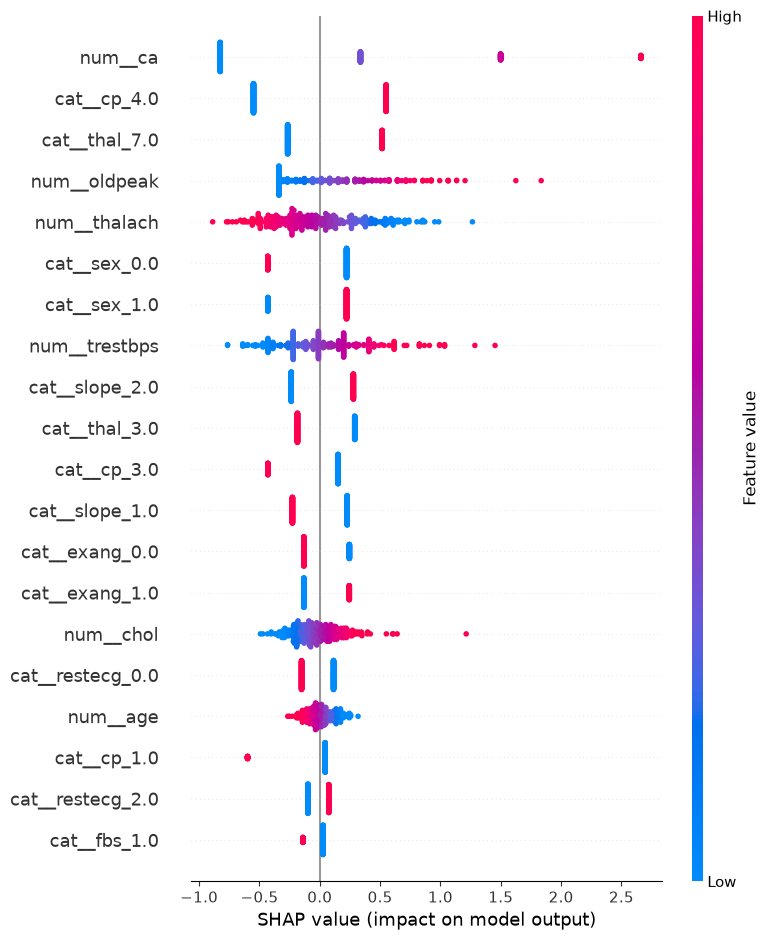

In [8]:
import shap, joblib
import matplotlib.pyplot as plt
from sklearn.base import clone

final = Pipeline([("prep", clone(preprocess)),
                  ("model", LogisticRegression(max_iter=1000))])
final.fit(X, y)   # all Cleveland patients, 13 features
joblib.dump(final, "model.joblib")

Xt = final.named_steps["prep"].transform(X)
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()
names = final.named_steps["prep"].get_feature_names_out()

explainer = shap.LinearExplainer(final.named_steps["model"], Xt)
sv = explainer.shap_values(Xt)
shap.summary_plot(sv, Xt, feature_names=names)